# **Exploracion del flujo migratorio de Guatemala**

Grupo 3 - CC3084 Data Science.


## **1. Preparacion de datos**

### **1.1. Carga de la fuente**

El archivo `Base_Migracion_2009-2026jun.xlsx` contiene informacion mensual sobre los ingresos de viajeros a Guatemala, desde enero de 2009 hasta junio de 2026. Para este analisis se carga la hoja `Datos`. La fuente permite estudiar el contexto nacional y su estacionalidad; por si sola no indica cuantas personas visitaron Atitlan.


In [1]:
from pathlib import Path
import pandas as pd

raiz_proyecto = Path.cwd()
if not (raiz_proyecto / "data" / "raw").is_dir():
    raiz_proyecto = raiz_proyecto.parent

ruta_datos = raiz_proyecto / "data" / "raw" / "Base_Migracion_2009-2026jun.xlsx"
datos = pd.read_excel(
    ruta_datos,
    sheet_name="Datos",
    dtype=str,
    keep_default_na=False,
)


### **1.2. Primeras cinco filas**

Se muestran las primeras cinco filas para reconocer como se organiza cada registro mensual y que variables contiene.


In [2]:
datos.head()


,Año,Mes cod,Mes,Vía,Frontera,País,Región,Región dos,Regiones OMT,MCEO,Agrupación Residencia,Tipo de Viajero,Viajero
0,2009,1,Ene,Aérea,01 La Aurora,Albania,OTROS EUROPEOS,Europa,EUROPA MERIDIONAL,08 OTROS,Europa,Turista,1
1,2009,1,Ene,Aérea,01 La Aurora,Alemania,EUROPA,Europa,EUROPA OCCIDENTAL,04 EUROPA,Europa,Turista,716
2,2009,1,Ene,Aérea,01 La Aurora,Angola,OTROS PAISES DEL MUNDO,Otros Paises Del Mundo,ÁFRICA CENTRAL,08 OTROS,Resto del Mundo,Turista,4
3,2009,1,Ene,Aérea,01 La Aurora,Arabia Saudita,OTROS ORIENTE MEDIO,Oriente Medio,ORIENTE MEDIO,08 OTROS,Resto del Mundo,Turista,5
4,2009,1,Ene,Aérea,01 La Aurora,Argelia,OTROS PAISES DEL MUNDO,Otros Paises Del Mundo,ÁFRICA DEL NORTE,08 OTROS,Resto del Mundo,Turista,1


### **1.3. Notas de la fuente**

El libro tambien incluye la hoja `Notas`, que explica el origen y alcance de los datos, sus categorias y los cambios de metodologia. Se muestra como referencia para interpretar la tabla; no se integra como si fueran registros de viajeros. La fuente indica uso academico y aclara que no son cifras oficiales.


In [3]:
notas = pd.read_excel(
    ruta_datos,
    sheet_name="Notas",
    header=None,
    names=["tema", "descripcion"],
    dtype=str,
    keep_default_na=False,
)
notas.loc[notas["descripcion"].ne("")]


,tema,descripcion
2,Origen y estatus,Ingreso de viajeros internacionales a Guatemal...
3,Cobertura,Enero 2009 a junio 2026: 210 meses consecutivo...
4,Estructura,Formato largo: una fila por combinación de mes...
5,Tipo de Viajero,Turista: pernocta al menos una noche. Excursio...
6,Cambio de granularidad en País (desde 2023),De 2009 a 2022 la columna 'País' trae país ind...
7,Quiebre metodológico 2022→2023,El tramo 2023+ proviene del sistema depurado (...
8,Procesamiento aplicado,2021-2022: agrupación de registros transaccion...
9,Quiebres a considerar,1) Vía Marítima pierde detalle desde 2017 (cam...


## **2. Descripcion de las variables**

Cada fila corresponde a una combinacion de mes, via de ingreso, frontera, pais o mercado, agrupacion de residencia y tipo de viajero. La cantidad de ingresos de esa combinacion se encuentra en `Viajero`.

- **Año:** anio al que corresponde el registro de ingresos; variable temporal de tipo cuantitativa discreta.

- **Mes cod:** numero del mes al que corresponde el registro; variable cualitativa ordinal de caracter ciclico.

- **Mes:** nombre abreviado del mes al que corresponde el registro, por ejemplo, `Ene`; variable cualitativa ordinal de caracter ciclico.

- **Vía:** medio por el que se ingresa al pais, clasificado como aereo, maritimo o terrestre; variable cualitativa nominal.

- **Frontera:** punto de ingreso al pais registrado en la fuente, como un aeropuerto, puerto o paso fronterizo; variable cualitativa nominal. Los numeros que forman parte de algunos nombres son codigos de identificacion y no indican un orden.

- **País:** pais o agrupacion de mercado al que corresponde el registro; variable cualitativa nominal. Hasta 2022 se reportan paises individuales y desde 2023 la fuente combina paises individuales con agrupaciones como `Otros Países de Europa`. Por eso no todos los valores representan un solo pais.

- **Región:** clasificacion regional asociada al pais o mercado del registro; variable cualitativa nominal.

- **Región dos:** segunda clasificacion regional utilizada por la fuente para agrupar los paises o mercados; variable cualitativa nominal.

- **Regiones OMT:** clasificacion geografica identificada por la fuente con la nomenclatura OMT, por ejemplo, America Central o Europa Occidental; variable cualitativa nominal.

- **MCEO:** clasificacion de mercados utilizada en la fuente, con categorias como Centroamerica, Norteamerica, Europa o BRICS; variable cualitativa nominal. Los codigos numericos que acompanan a algunas categorias no representan un orden.

- **Agrupación Residencia:** pais o conjunto de paises utilizado para agrupar la residencia de los viajeros; variable cualitativa nominal. Puede contener nombres de paises o grupos mas amplios, como Europa y Resto del Mundo.

- **Tipo de Viajero:** categoria del ingreso registrado, que puede ser Turista, Excursionista, Viajero o Cruceristas; variable cualitativa nominal. Segun las notas, Turista corresponde a quien pernocta, Excursionista a quien visita sin pernoctar y la categoria Viajero a cruces que no califican como visita turistica. La categoria Cruceristas tiene una cobertura diferente y deja de aparecer desde 2023.

- **Viajero:** cantidad de ingresos reportada para la combinacion del registro. Aunque conceptualmente es un conteo, la fuente incluye estimaciones expandidas con decimales, por lo que en su representacion actual es una variable cuantitativa continua. Esta columna contiene la medida numerica y es distinta de la categoria llamada `Viajero` dentro de `Tipo de Viajero`. No representa visitantes unicos del Lago de Atitlan.


## **3. Revision de calidad y exploracion de la serie**

### **3.1. Antecedentes y alcance de la reutilizacion**

Primero se contrasto este libro con los laboratorios anteriores, para poder recuperar el trabajo que corresponde a la misma fuente. El Excel es identico al de los laboratorios 1 y 2, y los CSV institucionales que utilizan los laboratorios 10 y 11 conservan las mismas particiones. Las copias sinteticas del ejercicio de recuperacion del Laboratorio 11 no se utilizaron como evidencia del turismo real.

| Laboratorio | Trabajo previo | Que se recupera aqui |
|---|---|---|
| 1. Series de tiempo | Filtrado de turistas y excursionistas, suma mensual, diagnosticos y comparacion de modelos. Entrenamiento hasta marzo de 2021 y prueba de abril de 2021 a junio de 2026. | Granularidad mensual, revision de estacionalidad y diagnosticos. Se revisa la poblacion antes de reutilizar la serie. |
| 2. Series de tiempo | LSTM para el total nacional y La Aurora; exploracion con catch22. | Evidencia de continuidad de los datos. No se trasladan redes, catch22 ni sus dependencias. |
| 10. Visualizacion | Contraste de SES, SARIMA y LSTM para el total y La Aurora. Normalizacion de vias y agrupaciones comparables para el tablero. | Revision de fronteras, separacion de residentes, anos parciales y porcentajes estacionales. |
| 11. MLOps | Un SARIMA nacional sobre logaritmos, ajustado con 2023-2025 y evaluado con enero-junio de 2026 frente al mismo mes del ano anterior. | Definicion de poblacion, controles de calidad, meses sin dato y evaluacion temporal del candidato. |

En los laboratorios 1 y 2, y en la comparacion de modelos del 10, el total incluye registros de `Guatemala` hasta 2022. En el 10 se excluyen de los agregados descriptivos y en el 11 tambien se excluyen de la serie del modelo, porque corresponden a residentes que regresan al pais. Para este proyecto se toma esta ultima definicion: ingresos de turistas y excursionistas no residentes. La exclusion se refiere a residencia segun esta base, no a nacionalidad.

Se revisaron los pipelines, configuraciones, contratos de datos, pruebas y consumo de resultados del tablero de los laboratorios 10 y 11. La interfaz, Docker, MLflow y los mecanismos de publicacion pertenecen a etapas posteriores; esta revision recupera solamente el diagnostico y los criterios que necesita este libro. Los calculos siguientes se hacen en memoria, sin guardar datos procesados.

**Referencias del trabajo previo:** [EDA del Laboratorio 1](../../Laboratorio_1_Series_de_Tiempo/notebooks/Eda_Inicial_Completo.ipynb), [modelos del Laboratorio 10](../../Laboratorio_10_Visualizacion/pipeline/src/04_modelos.py), [tipado del Laboratorio 10](../../Laboratorio_10_Visualizacion/pipeline/src/02_tipado.py), [preparacion del Laboratorio 11](../../Laboratorio_11_MLOps/pipeline/src/03_preparacion.py), [validacion del Laboratorio 11](../../Laboratorio_11_MLOps/pipeline/src/validacion.py), [configuracion del Laboratorio 11](../../Laboratorio_11_MLOps/pipeline/configuracion.toml) y [evaluacion guardada](../../Laboratorio_11_MLOps/pipeline/data/processed/05_evaluacion.json). Estos enlaces facilitan la consulta local; la ejecucion del notebook solo requiere el Excel de este proyecto y sus dependencias.


In [4]:
import hashlib
import numpy as np

huella_inicial = hashlib.sha256(ruta_datos.read_bytes()).hexdigest()
datos_originales = datos.copy(deep=True)
columnas_esperadas = [
    "Año", "Mes cod", "Mes", "Vía", "Frontera", "País", "Región", "Región dos",
    "Regiones OMT", "MCEO", "Agrupación Residencia", "Tipo de Viajero", "Viajero",
]
assert list(datos.columns) == columnas_esperadas
pd.DataFrame([{
    "archivo": ruta_datos.name, "filas": len(datos), "columnas": datos.shape[1],
    "sha256": huella_inicial,
    "coincide_excel_labs_1_y_2": huella_inicial == "cdaba77918ae889c847ba8459503f9cce2441efac41b3d3aa0f05ac9ab283846",
}])


,archivo,filas,columnas,sha256,coincide_excel_labs_1_y_2
0,Base_Migracion_2009-2026jun.xlsx,161036,13,cdaba77918ae889c847ba8459503f9cce2441efac41b3d...,True


### **3.2. Faltantes, categorias y conversion de tipos**

Se revisan vacios y marcadores de ausencia en las trece columnas. Los valores `0` y `0x2a` se inspeccionan por separado, ya que un cero en una cantidad no tiene el mismo significado que un cero utilizado como clasificacion regional.


In [5]:
MARCADORES_AUSENCIA = {"", "null", "none", "nan", "na", "n/a", "s/d"}
textos = datos.apply(lambda columna: columna.astype("string").str.strip())
faltantes = textos.apply(lambda columna: columna.isna() | columna.str.casefold().isin(MARCADORES_AUSENCIA))
resumen_columnas = pd.DataFrame({
    "faltantes": faltantes.sum(), "categorias_distintas": datos.nunique(dropna=False),
    "espacios_externos": datos.ne(textos).sum(),
})
revision = datos.copy(deep=True)
for origen, destino in [("Año", "anio"), ("Mes cod", "mes"), ("Viajero", "viajeros")]:
    revision[destino] = pd.to_numeric(textos[origen].mask(faltantes[origen]), errors="coerce")
revision["fecha"] = pd.to_datetime(dict(year=revision["anio"], month=revision["mes"], day=1), errors="coerce")
resumen_columnas


,faltantes,categorias_distintas,espacios_externos
Año,0,18,0
Mes cod,0,12,0
Mes,0,12,0
Vía,0,3,0
Frontera,0,22,0
País,0,235,0
Región,0,17,0
Región dos,0,11,0
Regiones OMT,0,26,0
MCEO,0,8,0


In [6]:
MESES = {1:"Ene", 2:"Feb", 3:"Mar", 4:"Abr", 5:"May", 6:"Jun", 7:"Jul", 8:"Ago", 9:"Sep", 10:"Oct", 11:"Nov", 12:"Dic"}
controles_numericos = pd.Series({
    "anio_no_numerico_o_no_finito": int((~np.isfinite(revision["anio"])).sum()),
    "anio_fraccionario": int(revision["anio"].mod(1).ne(0).sum()),
    "mes_fuera_de_1_a_12_o_fraccionario": int((~revision["mes"].between(1,12) | revision["mes"].mod(1).ne(0)).sum()),
    "fecha_invalida": int(revision["fecha"].isna().sum()),
    "nombre_mes_inconsistente": int(datos["Mes"].ne(revision["mes"].map(MESES)).sum()),
    "viajeros_no_numericos_o_no_finitos": int((~np.isfinite(revision["viajeros"])).sum()),
    "viajeros_negativos": int(revision["viajeros"].lt(0).sum()),
    "viajeros_cero": int(revision["viajeros"].eq(0).sum()),
    "viajeros_con_fraccion": int((revision["viajeros"].sub(revision["viajeros"].round()).abs() > 1e-8).sum()),
}, name="registros")
controles_numericos.to_frame()


,registros
anio_no_numerico_o_no_finito,0
anio_fraccionario,0
mes_fuera_de_1_a_12_o_fraccionario,0
fecha_invalida,0
nombre_mes_inconsistente,0
viajeros_no_numericos_o_no_finitos,0
viajeros_negativos,0
viajeros_cero,54
viajeros_con_fraccion,43009


In [7]:
columnas_categoricas = ["Vía", "Tipo de Viajero", "Región", "Región dos", "Regiones OMT", "MCEO", "Agrupación Residencia"]
catalogos = pd.concat([
    datos[columna].value_counts(dropna=False).rename_axis("valor").reset_index(name="registros").assign(variable=columna)
    for columna in columnas_categoricas
], ignore_index=True)[["variable", "valor", "registros"]]
# Tabla desplegable completa; no se limita al head para revisar todos los catalogos.
with pd.option_context("display.max_rows", None):
    display(catalogos)


,variable,valor,registros
0,Vía,Terrestre,125873
1,Vía,Aérea,24999
2,Vía,Marítima,10164
3,Tipo de Viajero,Turista,117912
4,Tipo de Viajero,Viajero,23190
5,Tipo de Viajero,Excursionista,19730
6,Tipo de Viajero,Cruceristas,204
7,Región,EUROPA,32331
8,Región,AMÉRICA DEL CENTRO,31362
9,Región,OTROS EUROPEOS,22309


In [8]:
import unicodedata

# Se detectan diferencias de escritura sin unificar paises por similitud de nombre.
variantes_escritura = []
problemas_texto = []
for columna in datos.columns:
    valores = datos[columna].drop_duplicates()
    normalizados = valores.map(lambda valor: unicodedata.normalize("NFC", valor).strip().casefold())
    for etiqueta, indices in normalizados.groupby(normalizados).groups.items():
        originales = valores.loc[indices].tolist()
        if len(originales) > 1:
            variantes_escritura.append({"variable":columna, "variantes":originales})
    sospechosos = valores[valores.map(lambda valor: any(marca in valor for marca in ["Ã", "�", "Â"]) or any(ord(caracter) < 32 for caracter in valor))]
    for valor in sospechosos:
        problemas_texto.append({"variable":columna, "valor":valor})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(variantes_escritura, columns=["variable","variantes"]))
display(pd.DataFrame(problemas_texto, columns=["variable","valor"]))
# El cambio de categorias se inspecciona completo, sin asumir pais = pais individual.
mercados_por_regimen = pd.crosstab(datos["País"], np.where(revision["anio"].ge(2023), "desde_2023", "hasta_2022"))
with pd.option_context("display.max_rows", None):
    display(mercados_por_regimen)

normalizacion_pais = datos["País"].map(lambda valor: unicodedata.normalize("NFC", valor).strip().casefold())
pais_canonico = datos.groupby(normalizacion_pais, sort=False)["País"].first()
pais_propuesto = normalizacion_pais.map(pais_canonico)
display(pd.Series({"grupos_de_variantes_de_pais": len([v for v in variantes_escritura if v["variable"] == "País"]), "filas_cuyo_formato_cambiaria": int(pais_propuesto.ne(datos["País"]).sum())}).to_frame("cantidad"))


,variable,variantes
0,País,"[Antigua y Barbuda, Antigua Y Barbuda]"
1,País,"[Bolivia (Estado Plurinacional de), Bolivia (Estado Plurinacional De)]"
2,País,"[Côte d'Ivoire, Côte D'ivoire]"
3,País,"[Federación de Rusia, Federación De Rusia]"
4,País,"[Irán (República Islámica del), Irán (República Islámica Del)]"
5,País,"[Micronesia (Estados Federados de), Micronesia (Estados Federados De)]"
6,País,"[OTROS PAISES DEL MUNDO, Otros Paises Del Mundo]"
7,País,"[Reino Unido de Gran Bretaña e Irlanda del Norte, Reino Unido De Gran Bretaña E Irlanda Del Norte]"
8,País,"[República de Corea, República De Corea]"
9,País,"[República de Moldova, República De Moldova]"


,variable,valor


col_0,desde_2023,hasta_2022
País,,
Afganistán,0,165
Albania,0,192
Alemania,840,2635
Andorra,0,187
Angola,0,52
Anguila,0,17
Antigua Y Barbuda,0,2
Antigua y Barbuda,0,109
Arabia Saudita,0,229


,cantidad
grupos_de_variantes_de_pais,13
filas_cuyo_formato_cambiaria,51


No aparecen vacios ni marcadores habituales de ausencia en la fuente. Sin embargo, `Región dos` contiene `0` en 13 registros y `Regiones OMT` contiene `0x2a` en 5 de ellos. Son etiquetas sin significado regional documentado, no cantidades. `SIN ESPECIFICAR` expresa una clasificacion desconocida y se distingue de esas etiquetas invalidas. En residencia tambien aparecen `Resto de mundo` y `Resto del Mundo`, que difieren en escritura.

En pais se detectan 13 parejas de etiquetas que solo difieren en mayusculas y minusculas, por ejemplo `Antigua y Barbuda` y `Antigua Y Barbuda`. Adoptar como etiqueta la primera forma registrada cambiaria el formato de 51 filas, sin cambiar el mercado al que corresponden. La revision no detecta los patrones de texto mal codificado ni caracteres de control que se buscaron; esto no equivale a validar cada nombre contra un catalogo institucional externo.


In [9]:
anomalias_regionales = datos["Región dos"].eq("0") | datos["Regiones OMT"].eq("0x2a")
datos.loc[anomalias_regionales, ["Año", "Mes cod", "País", "Región", "Región dos", "Regiones OMT", "Agrupación Residencia", "Viajero"]]


,Año,Mes cod,País,Región,Región dos,Regiones OMT,Agrupación Residencia,Viajero
136757,2022,1,Islas Vírgenes Americanas,OTROS CARIBEÑOS,0,EL CARIBE,Resto de mundo,43
137478,2022,2,Islas Vírgenes Americanas,OTROS CARIBEÑOS,0,EL CARIBE,Resto de mundo,48
137620,2022,2,República Democrática del Congo,OTROS PAISES DEL MUNDO,0,0x2a,Resto de mundo,1
137621,2022,2,República Democrática del Congo,OTROS PAISES DEL MUNDO,0,0x2a,Resto de mundo,1
138151,2022,3,Islas Vírgenes Americanas,OTROS CARIBEÑOS,0,EL CARIBE,Resto de mundo,53
139040,2022,4,República Democrática del Congo,OTROS PAISES DEL MUNDO,0,0x2a,Resto de mundo,11
140255,2022,6,República Democrática del Congo,OTROS PAISES DEL MUNDO,0,0x2a,Resto de mundo,11
140556,2022,7,Islas Vírgenes Americanas,OTROS CARIBEÑOS,0,EL CARIBE,Resto de mundo,79
141198,2022,8,Islas Vírgenes Americanas,OTROS CARIBEÑOS,0,EL CARIBE,Resto de mundo,81
141788,2022,9,Islas Vírgenes Americanas,OTROS CARIBEÑOS,0,EL CARIBE,Resto de mundo,88


### **3.3. Unicidad y nivel de detalle**

Se comparan filas completas y dos claves. La clave parcial puede coincidir en filas cuya agrupacion de residencia es distinta, por lo que esa coincidencia no justifica borrar registros. Se revisa tambien la dependencia entre las clasificaciones regionales para evitar suponer que una es copia de otra.


In [10]:
clave_parcial = ["Año", "Mes cod", "Vía", "Frontera", "País", "Tipo de Viajero"]
clave_completa = clave_parcial + ["Agrupación Residencia"]
coincidencias_parciales = datos.duplicated(clave_parcial, keep=False)
resumen_unicidad = pd.DataFrame([
    {"revision": "fila original completa", "repeticiones_adicionales": int(datos.duplicated().sum()), "filas_involucradas": int(datos.duplicated(keep=False).sum())},
    {"revision": "clave parcial", "repeticiones_adicionales": int(datos.duplicated(clave_parcial).sum()), "filas_involucradas": int(coincidencias_parciales.sum())},
    {"revision": "clave con agrupacion de residencia", "repeticiones_adicionales": int(datos.duplicated(clave_completa).sum()), "filas_involucradas": int(datos.duplicated(clave_completa, keep=False).sum())},
])
display(resumen_unicidad)
display(datos.loc[coincidencias_parciales, clave_completa + ["Viajero"]].head(12))
pd.crosstab(datos["Región"], datos["Región dos"])


,revision,repeticiones_adicionales,filas_involucradas
0,fila original completa,0,0
1,clave parcial,22,42
2,clave con agrupacion de residencia,0,0


,Año,Mes cod,Vía,Frontera,País,Tipo de Viajero,Agrupación Residencia,Viajero
130128,2020,12,Terrestre,15 El Carmen,Reino Unido de Gran Bretaña e Irlanda del Norte,Turista,Europa,3
130129,2020,12,Terrestre,15 El Carmen,Reino Unido de Gran Bretaña e Irlanda del Norte,Turista,Resto del Mundo,1
131981,2021,5,Aérea,01 La Aurora,Federación de Rusia,Turista,Europa,44
131982,2021,5,Aérea,01 La Aurora,Federación de Rusia,Turista,Resto del Mundo,223
132717,2021,6,Terrestre,12 El Florido,Reino Unido de Gran Bretaña e Irlanda del Norte,Turista,Europa,4
132718,2021,6,Terrestre,12 El Florido,Reino Unido de Gran Bretaña e Irlanda del Norte,Turista,Resto del Mundo,1
133281,2021,7,Terrestre,15 El Carmen,Estados Unidos de América,Excursionista,Estados Unidos de América,7
133282,2021,7,Terrestre,15 El Carmen,Estados Unidos de América,Excursionista,México,13
138849,2022,4,Aérea,01 La Aurora,Colombia,Turista,Colombia,2610
138850,2022,4,Aérea,01 La Aurora,Colombia,Turista,Otros Suramérica,1051


Región dos,0,América Del Centro,América Del Norte,América Del Sur y el Caribe,Asia,Cruceristas,Cruceros,Europa,Oceanía,Oriente Medio,Otros Paises Del Mundo
Región,,,,,,,,,,,
AMÉRICA DEL CENTRO,0,31362,0,0,0,0,0,0,0,0,0
AMÉRICA DEL NORTE,0,0,17306,0,0,0,0,0,0,0,0
AMÉRICA DEL SUR,0,0,0,15969,0,0,0,0,0,0,0
ASIA,0,0,0,0,6797,0,0,0,0,0,0
Cruceristas,0,0,0,0,0,196,0,0,0,0,0
Cruceros,0,0,0,0,0,0,8,0,0,0,0
EL CARIBE,0,0,0,2214,0,0,0,0,0,0,0
EUROPA,0,0,0,0,0,0,0,32331,0,0,0
OCEANÍA,0,0,0,0,0,0,0,0,4478,0,0


La fuente tiene 42 filas involucradas en coincidencias de la clave parcial, distribuidas en 20 grupos. Al incluir la agrupacion de residencia no quedan repeticiones. Por eso se conservan las filas y se mantiene esa columna en el detalle. Las clasificaciones regionales contienen niveles y combinaciones diferentes; no se retiran automaticamente por tener nombres similares.


### **3.4. Coherencia entre via y frontera**

El Laboratorio 10 asigna la via a partir del codigo fronterizo: `01` y `02` son aereos, `03` a `06` maritimos y los restantes puestos conocidos son terrestres. Aqui se contrasta esa regla con todos los puestos observados, sin reemplazar la via original ni asignar una via por defecto a codigos desconocidos.


In [11]:
VIAS_POR_CODIGO = {"01":"Aérea", "02":"Aérea", "03":"Marítima", "04":"Marítima", "05":"Marítima", "06":"Marítima"}
codigos_observados = sorted(datos["Frontera"].str.extract(r"^(\d{2})\s", expand=False).dropna().unique())
# El rango de puestos se verifica sobre el catalogo de esta fuente.
catalogo_fronteras = datos.groupby("Frontera")["Vía"].agg(lambda valores: ", ".join(sorted(valores.unique()))).to_frame("vias_en_origen")
codigos_terrestres = {f"{numero:02d}" for numero in range(7,23)}
mapa_vias = {**VIAS_POR_CODIGO, **{codigo:"Terrestre" for codigo in codigos_terrestres}}
codigos = datos["Frontera"].str.extract(r"^(\d{2})\s", expand=False)
via_esperada = codigos.map(mapa_vias)
discrepancias_via = via_esperada.notna() & datos["Vía"].ne(via_esperada)
display(catalogo_fronteras)
display(pd.Series({"codigo_sin_mapa": int(via_esperada.isna().sum()), "via_inconsistente": int(discrepancias_via.sum())}).to_frame("registros"))
datos.loc[discrepancias_via, ["Año", "Mes cod", "Frontera", "Vía", "País", "Tipo de Viajero", "Viajero"]].assign(via_esperada=via_esperada[discrepancias_via]).head(10)


,vias_en_origen
Frontera,
01 La Aurora,"Aérea, Terrestre"
02 Mundo Maya,"Aérea, Terrestre"
03 Puerto Quetzal,Marítima
04 Santo Tomás de Castilla,Marítima
05 Puerto Barrios,Marítima
06 Livingston,Marítima
07 Valle Nuevo,Terrestre
08 Pedro de Alvarado,Terrestre
09 San Cristóbal,Terrestre


,registros
codigo_sin_mapa,8
via_inconsistente,93


,Año,Mes cod,Frontera,Vía,País,Tipo de Viajero,Viajero,via_esperada
134309,2021,10,01 La Aurora,Terrestre,Afganistán,Turista,1,Aérea
134310,2021,10,01 La Aurora,Terrestre,Alemania,Turista,183,Aérea
134311,2021,10,01 La Aurora,Terrestre,Argentina,Turista,269,Aérea
134312,2021,10,01 La Aurora,Terrestre,Australia,Turista,32,Aérea
134313,2021,10,01 La Aurora,Terrestre,Austria,Turista,6,Aérea
134314,2021,10,01 La Aurora,Terrestre,Bahamas,Turista,4,Aérea
134315,2021,10,01 La Aurora,Terrestre,Bangladesh,Turista,1,Aérea
134316,2021,10,01 La Aurora,Terrestre,Barbados,Turista,3,Aérea
134317,2021,10,01 La Aurora,Terrestre,Bolivia (Estado Plurinacional de),Turista,45,Aérea
134318,2021,10,01 La Aurora,Terrestre,Brasil,Turista,198,Aérea


Se encuentran 93 registros con discrepancia: 92 de 2021 y uno de 2022. Esta diferencia afecta los desgloses por via, pero no cambia el total nacional si se conservan las cantidades. La correccion del Laboratorio 10 es aprovechable para los puestos conocidos; un nuevo codigo debe generar una incidencia, sin asumir que es terrestre.


In [12]:
# Simulacion de impacto: no sustituye datos ni aplica la limpieza definitiva.
revision_claves = datos.copy(deep=True)
revision_claves["Vía"] = via_esperada
revision_claves["País"] = pais_propuesto
revision_claves["Agrupación Residencia"] = revision_claves["Agrupación Residencia"].replace({"Resto de mundo":"Resto del Mundo"})
colisiones_tras_reparar = revision_claves.duplicated(clave_completa, keep=False)
display(pd.Series({
    "filas_en_colisiones_tras_normalizar": int(colisiones_tras_reparar.sum()),
    "grupos_en_colision": int(revision_claves.loc[colisiones_tras_reparar,clave_completa].drop_duplicates().shape[0]),
    "repeticiones_de_clave_adicionales": int(revision_claves.duplicated(clave_completa).sum()),
    "filas_exactamente_iguales_tras_normalizar": int(revision_claves.duplicated().sum()),
}).to_frame("registros_o_grupos"))
datos.loc[colisiones_tras_reparar, clave_completa+["Viajero"]].assign(fila_excel=lambda tabla: tabla.index+2).head(8)

,registros_o_grupos
filas_en_colisiones_tras_normalizar,40
grupos_en_colision,20
repeticiones_de_clave_adicionales,20
filas_exactamente_iguales_tras_normalizar,1


,Año,Mes cod,Vía,Frontera,País,Tipo de Viajero,Agrupación Residencia,Viajero,fila_excel
134251,2021,10,Aérea,01 La Aurora,Alemania,Turista,Europa,222,134253
134252,2021,10,Aérea,01 La Aurora,Austria,Turista,Europa,44,134254
134256,2021,10,Aérea,01 La Aurora,Bulgaria,Turista,Europa,6,134258
134257,2021,10,Aérea,01 La Aurora,Bélgica,Turista,Europa,68,134259
134266,2021,10,Aérea,01 La Aurora,España,Turista,Europa,286,134268
134268,2021,10,Aérea,01 La Aurora,Estonia,Turista,Europa,7,134270
134269,2021,10,Aérea,01 La Aurora,Federación de Rusia,Turista,Europa,69,134271
134271,2021,10,Aérea,01 La Aurora,Francia,Turista,Europa,190,134273


Al simular la normalizacion de via y residencia aparecen 40 filas en 20 grupos con la misma clave; una pareja incluso queda identica en todas las columnas. Esto ocurre en octubre de 2021 y no demuestra por si solo que sean los mismos ingresos. Se conservan las cantidades y la fila de origen, sin aplicar `drop_duplicates` despues de reparar. El total mensual mantendra el criterio aditivo de los laboratorios, documentando que la posible superposicion de esos registros no puede descartarse con este archivo. Esta incidencia es anterior a la ventana de ajuste 2023-2025.


### **3.5. Poblacion y cobertura de la serie**

Primero se cuantifica el filtro de turistas y excursionistas, y despues se separan los residentes de Guatemala. Esto permite comparar la definicion historica con la del Laboratorio 11 sin confundir un cambio de poblacion con una correccion de valores.


In [13]:
TIPOS_INCLUIDOS = {"Turista", "Excursionista"}
es_visitante = datos["Tipo de Viajero"].isin(TIPOS_INCLUIDOS)
es_residente = datos["País"].eq("Guatemala")
es_poblacion_objetivo = es_visitante & ~es_residente
revision["periodo_metodologico"] = np.select([revision["anio"].le(2020), revision["anio"].le(2022)], ["2009-2020", "2021-2022"], default="2023-2026")
display(datos["Tipo de Viajero"].value_counts().to_frame("registros"))
display(pd.DataFrame([
    {"poblacion": "fuente completa", "registros": len(datos)},
    {"poblacion": "turistas y excursionistas (labs 1 y 2)", "registros": int(es_visitante.sum())},
    {"poblacion": "residentes dentro de turistas y excursionistas", "registros": int((es_visitante & es_residente).sum())},
    {"poblacion": "turistas y excursionistas sin residentes (lab 11)", "registros": int(es_poblacion_objetivo.sum())},
]))
calendario = pd.date_range(revision["fecha"].min(), revision["fecha"].max(), freq="MS", name="fecha")
serie_historica = revision.loc[es_visitante].groupby("fecha")["viajeros"].sum(min_count=1).reindex(calendario)
serie_mensual = revision.loc[es_poblacion_objetivo].groupby("fecha")["viajeros"].sum(min_count=1).reindex(calendario)
registros_mensuales = revision.loc[es_poblacion_objetivo].groupby("fecha").size().reindex(calendario, fill_value=0)
comparacion_poblaciones = pd.DataFrame({"total_con_residentes": serie_historica, "total_sin_residentes": serie_mensual, "registros_sin_residentes": registros_mensuales})
display(comparacion_poblaciones.loc["2020-03":"2020-09"])
pd.DataFrame({"meses_calendario":[len(calendario)], "meses_sin_registros_poblacion_objetivo":[int(serie_mensual.isna().sum())], "meses_con_total_cero":[int(serie_mensual.eq(0).sum())]})


,registros
Tipo de Viajero,
Turista,117912
Viajero,23190
Excursionista,19730
Cruceristas,204


,poblacion,registros
0,fuente completa,161036
1,turistas y excursionistas (labs 1 y 2),137642
2,residentes dentro de turistas y excursionistas,4748
3,turistas y excursionistas sin residentes (lab 11),132894


,total_con_residentes,total_sin_residentes,registros_sin_residentes
fecha,,,
2020-03-01,155415.576092,87659.576092,608
2020-04-01,10039.0,<NA>,0
2020-05-01,9779.0,<NA>,0
2020-06-01,11817.0,<NA>,0
2020-07-01,13484.0,<NA>,0
2020-08-01,15357.0,<NA>,0
2020-09-01,12572.492683,1932.492683,120


,meses_calendario,meses_sin_registros_poblacion_objetivo,meses_con_total_cero
0,210,5,0


In [14]:
resumen_periodos = revision.groupby("periodo_metodologico").agg(registros=("viajeros", "size"), paises_o_mercados=("País", "nunique"), inicio=("fecha", "min"), fin=("fecha", "max"))
revision["es_residente_visitante"] = es_visitante & es_residente
resumen_periodos["residentes_visitantes"] = revision.groupby("periodo_metodologico")["es_residente_visitante"].sum()
display(resumen_periodos)
cobertura_anual = revision.groupby("anio")["fecha"].nunique().rename("meses_en_fuente")
display(cobertura_anual.to_frame().assign(anio_completo=cobertura_anual.eq(12)))
comparacion_poblaciones.loc["2026-01":"2026-02"]


,registros,paises_o_mercados,inicio,fin,residentes_visitantes
periodo_metodologico,,,,,
2009-2020,130211,226,2009-01-01,2020-12-01,4217
2021-2022,13846,199,2021-01-01,2022-12-01,531
2023-2026,16979,26,2023-01-01,2026-06-01,0


,meses_en_fuente,anio_completo
anio,,
2009,12,True
2010,12,True
2011,12,True
2012,12,True
2013,12,True
2014,12,True
2015,12,True
2016,12,True
2017,12,True


,total_con_residentes,total_sin_residentes,registros_sin_residentes
fecha,,,
2026-01-01,300664.075273,300664.075273,286
2026-02-01,236844.113618,236844.113618,261


De los 161,036 registros, 137,642 son turistas o excursionistas; al excluir 4,748 registros de residentes quedan 132,894. La rejilla tiene 210 meses, pero la poblacion sin residentes no tiene registros de abril a agosto de 2020. Se representan como faltantes, sin convertirlos en cero ni rellenarlos con el minimo observado, como se hizo en algunas series regionales del Laboratorio 1.

La hoja de notas distingue cambios de fuente y cobertura en 2021 y 2023, ademas del efecto de la pandemia y del cambio de detalle maritimo desde 2017. Desde 2023 se observan 26 categorias de pais o mercado, aunque la nota menciona 27. Esa diferencia queda registrada; no se inventa una categoria adicional ni se toma cada mercado agrupado como si fuera un pais individual.

Enero y febrero de 2026 **si tienen observaciones nacionales**. Los meses sin cobertura que interesan al proyecto son los de movilidad de Atitlan, otra fuente y otra poblacion. Predecir ingresos al pais no equivale a estimar visitantes del lago. Asimismo, 2026 solo llega a junio, por lo que no se compara su suma con anos completos.


### **3.6. Cantidades, decimales y valores extremos**

Los ingresos son conceptualmente un conteo, pero la fuente academica utiliza cantidades expandidas con decimales. Se conserva su precision. Se revisan ceros y valores extremos como evidencia, sin asumir que una fila grande es incorrecta, ya que las filas representan mercados y fronteras con volumenes muy diferentes.


In [15]:
con_fraccion = revision["viajeros"].sub(revision["viajeros"].round()).abs().gt(1e-8)
display(revision.loc[con_fraccion, ["Año", "Mes cod", "Frontera", "País", "Tipo de Viajero", "viajeros"]].head(5))
display(revision.loc[revision["viajeros"].eq(0)].groupby(["anio", "Tipo de Viajero"]).size().to_frame("registros_cero"))
q1, q3 = revision["viajeros"].quantile([0.25,0.75])
atipicos_iqr = revision["viajeros"].gt(q3 + 1.5 * (q3 - q1)) | revision["viajeros"].lt(q1 - 1.5 * (q3 - q1))
display(pd.Series({"registros_marcados_iqr": int(atipicos_iqr.sum()), "porcentaje_ingresos_en_esos_registros": revision.loc[atipicos_iqr,"viajeros"].sum()/revision["viajeros"].sum()*100}).to_frame("valor"))
revision.nlargest(5,"viajeros")[["Año", "Mes cod", "Frontera", "País", "Tipo de Viajero", "viajeros"]]


,Año,Mes cod,Frontera,País,Tipo de Viajero,viajeros
172,2009,1,03 Puerto Quetzal,Cruceristas,Cruceristas,6518.96858
182,2009,1,04 Santo Tomás de Castilla,Cruceristas,Cruceristas,6051.03142
260,2009,1,07 Valle Nuevo,Canadá,Excursionista,4.656522
261,2009,1,07 Valle Nuevo,Canadá,Turista,83.817391
262,2009,1,07 Valle Nuevo,Canadá,Viajero,64.526087


registros_cero
anio Tipo de Viajero                
2020 Excursionista                 3
     Turista                      37
     Viajero                      14

,valor
registros_marcados_iqr,26390.000000
porcentaje_ingresos_en_esos_registros,96.677508


,Año,Mes cod,Frontera,País,Tipo de Viajero,viajeros
98206,2017,8,20 Melchor de Mencos,Belice,Viajero,92336.035067
124846,2019,12,01 La Aurora,Guatemala,Turista,83511.0
113144,2018,12,01 La Aurora,Guatemala,Turista,81030.06108
143464,2022,12,01 La Aurora,Guatemala,Turista,76588.0
101056,2017,12,01 La Aurora,Guatemala,Turista,72545.0


Hay 54 registros con cero, todos de 2020, y 43,009 con fraccion real. Se conservan ambos casos. El criterio IQR sobre filas marca una parte importante del volumen, por lo que no se utiliza como filtro de eliminacion. Los cambios fuertes se interpretan junto con la pandemia, la composicion del mercado y los cambios de fuente.


### **3.7. Exploracion temporal alineada con el Laboratorio 11**

Se separan enero de 2023 a diciembre de 2025 para el diagnostico del candidato, y enero a junio de 2026 como evaluacion historica reservada. Esto recupera el protocolo del Laboratorio 11, sin afirmar que tres ciclos anuales sean suficientes para garantizar estabilidad. La serie mas antigua se conserva como contexto, con sus cambios metodologicos y meses sin registros.


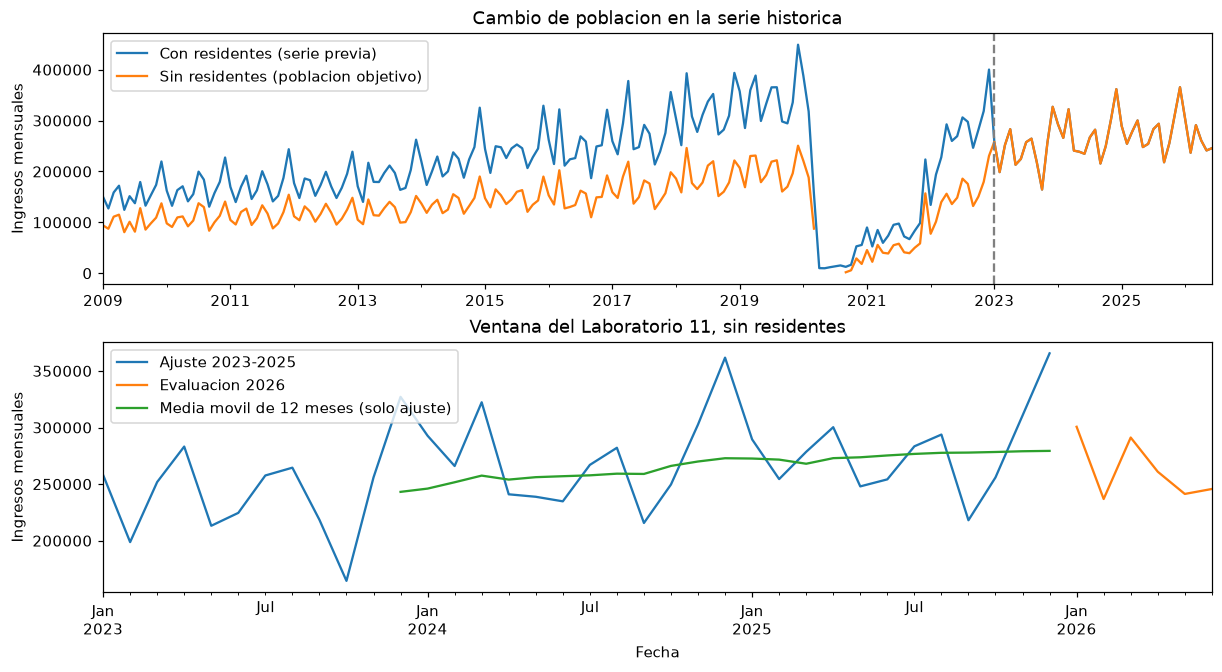

In [16]:
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

serie_ajuste = serie_mensual.loc["2023-01":"2025-12"].copy()
serie_evaluacion = serie_mensual.loc["2026-01":"2026-06"].copy()
assert len(serie_ajuste) == 36 and len(serie_evaluacion) == 6
assert serie_ajuste.notna().all() and serie_ajuste.gt(0).all()
assert serie_evaluacion.notna().all() and serie_evaluacion.gt(0).all()
assert serie_ajuste.index.max() < serie_evaluacion.index.min()
assert np.isclose(serie_mensual.sum(), revision.loc[es_poblacion_objetivo,"viajeros"].sum(), rtol=1e-12, atol=1e-6)
fig, ejes = plt.subplots(2, 1, figsize=(11, 6), layout="constrained")
comparacion_poblaciones[["total_con_residentes","total_sin_residentes"]].rename(columns={"total_con_residentes":"Con residentes (serie previa)", "total_sin_residentes":"Sin residentes (poblacion objetivo)"}).plot(ax=ejes[0])
ejes[0].axvline(pd.Timestamp("2023-01-01"), color="gray", linestyle="--")
ejes[0].set(title="Cambio de poblacion en la serie historica", ylabel="Ingresos mensuales", xlabel="")
serie_ajuste.plot(ax=ejes[1], label="Ajuste 2023-2025")
serie_evaluacion.plot(ax=ejes[1], label="Evaluacion 2026")
serie_ajuste.rolling(12, min_periods=12).mean().plot(ax=ejes[1], label="Media movil de 12 meses (solo ajuste)")
ejes[1].set(title="Ventana del Laboratorio 11, sin residentes", ylabel="Ingresos mensuales", xlabel="Fecha")
ejes[1].legend()
plt.show()


,porcentaje_promedio,minimo,maximo,anios
mes,,,,
1,8.808334,8.637192,8.939917,3
2,7.5082,6.81164,8.123252,3
3,8.927732,8.308898,9.843234,3
4,8.67418,7.359705,9.705143,3
5,7.332332,7.293102,7.397392,3
6,7.48318,7.170127,7.69683,3
7,8.478771,8.153311,8.829412,3
8,8.81477,8.61528,9.065449,3
9,6.859739,6.505093,7.487987,3


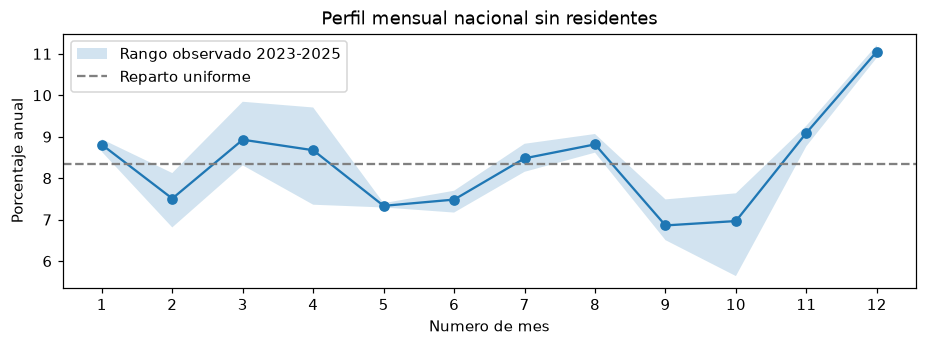

In [17]:
# Primero se suman los registros de cada mes; luego se calcula su peso anual.
# No se promedian directamente las filas originales, que tienen distinto nivel de volumen.
perfil_base = serie_ajuste.rename("viajeros").to_frame()
perfil_base["anio"] = perfil_base.index.year
perfil_base["mes"] = perfil_base.index.month
perfil_base["porcentaje_anual"] = 100*perfil_base["viajeros"]/perfil_base.groupby("anio")["viajeros"].transform("sum")
perfil_estacional = perfil_base.groupby("mes")["porcentaje_anual"].agg(["mean","min","max","count"]).rename(columns={"mean":"porcentaje_promedio","min":"minimo","max":"maximo","count":"anios"})
assert np.isclose(perfil_estacional["porcentaje_promedio"].sum(), 100)
display(perfil_estacional)
fig, eje = plt.subplots(figsize=(10,3))
eje.plot(perfil_estacional.index, perfil_estacional["porcentaje_promedio"], marker="o")
eje.fill_between(perfil_estacional.index, perfil_estacional["minimo"], perfil_estacional["maximo"], alpha=0.2, label="Rango observado 2023-2025")
eje.axhline(100/12, linestyle="--", color="gray", label="Reparto uniforme")
eje.set(xticks=range(1,13), xlabel="Numero de mes", ylabel="Porcentaje anual", title="Perfil mensual nacional sin residentes")
eje.legend()
plt.show()


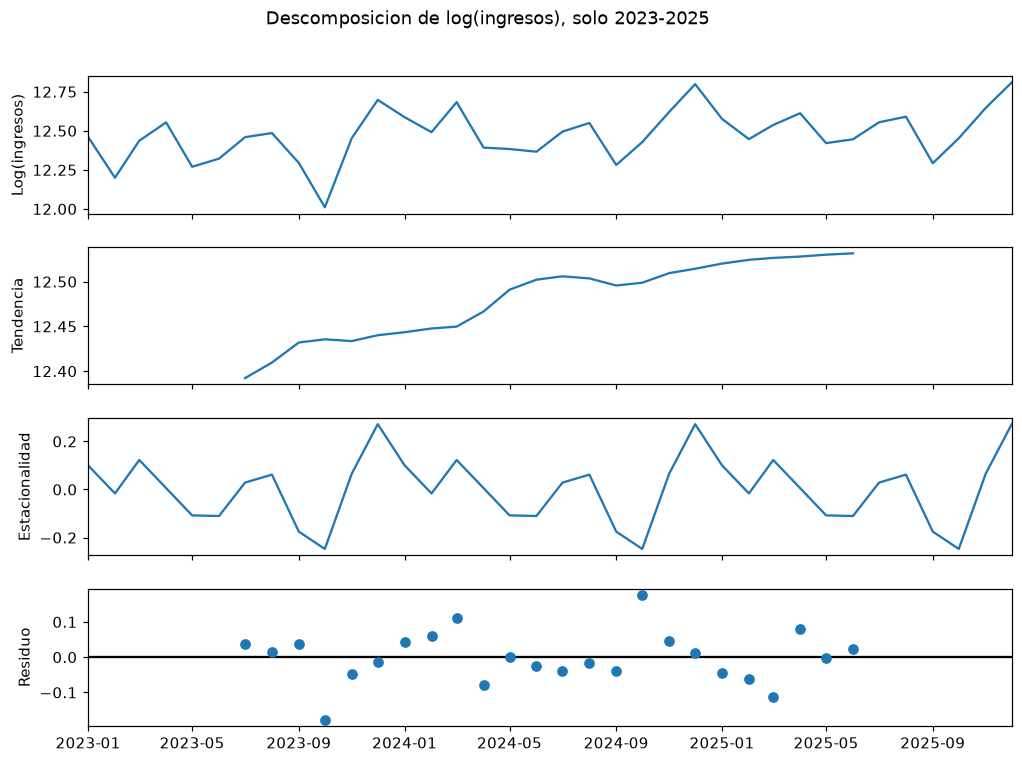

,serie,estadistico_adf,p_valor,rezagos,observaciones
0,log_nivel,-2.031169,0.273076,10,25
1,log_diferencia_1,-3.640984,0.005024,10,24
2,log_diferencia_1_y_estacional_12,-3.084908,0.027690,9,13


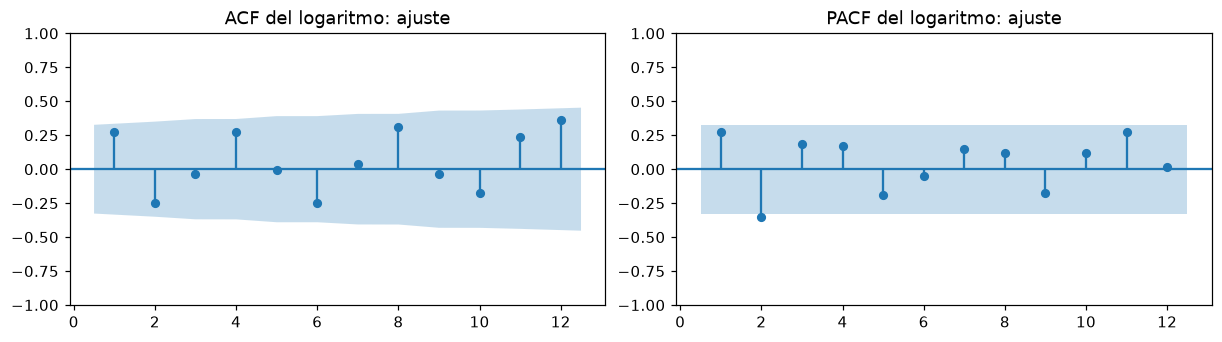

In [18]:
log_ajuste = np.log(serie_ajuste)
descomposicion = seasonal_decompose(log_ajuste, model="additive", period=12)
fig = descomposicion.plot()
fig.set_size_inches(10,7)
for eje, etiqueta in zip(fig.axes, ["Log(ingresos)", "Tendencia", "Estacionalidad", "Residuo"]):
    eje.set_ylabel(etiqueta)
fig.axes[0].set_title("")
fig.suptitle("Descomposicion de log(ingresos), solo 2023-2025", y=1.01)
plt.show()
# Diferenciar una vez no significa diff(d): diff(2) seria un rezago de dos meses.
series_diagnostico = {
    "log_nivel": log_ajuste,
    "log_diferencia_1": log_ajuste.diff().dropna(),
    "log_diferencia_1_y_estacional_12": log_ajuste.diff().diff(12).dropna(),
}
resultados_adf = []
for nombre, serie in series_diagnostico.items():
    estadistico, p_valor, rezagos, n_obs, *_ = adfuller(serie, regression="c", autolag="AIC")
    resultados_adf.append({"serie":nombre, "estadistico_adf":estadistico, "p_valor":p_valor, "rezagos":rezagos, "observaciones":n_obs})
display(pd.DataFrame(resultados_adf))
fig, ejes = plt.subplots(1,2,figsize=(11,3),layout="constrained")
plot_acf(log_ajuste, lags=12, ax=ejes[0], zero=False)
plot_pacf(log_ajuste, lags=12, ax=ejes[1], zero=False, method="ywm")
ejes[0].set_title("ACF del logaritmo: ajuste")
ejes[1].set_title("PACF del logaritmo: ajuste")
plt.show()


En 2023-2025, diciembre concentra el mayor porcentaje mensual promedio (11.05 % del total anual) y septiembre el menor (6.86 %). Es un patron nacional de tres anos, no una medida de temporada de Atitlan.

La descomposicion permite reconocer tendencia y estacionalidad en la ventana reciente. La prueba ADF contrasta la hipotesis de raiz unitaria bajo su especificacion; un valor p pequeno no garantiza que toda la serie sea estable ni valida por si solo un orden SARIMA. Con 36 observaciones, las diferencias reducen aun mas la informacion y la lectura de ACF y PACF debe ser prudente. Estos diagnosticos utilizan solamente el ajuste, sin elegir parametros a partir de los seis meses reservados.

En el logaritmo sin diferencias, ADF obtiene un valor p de 0.273; con una diferencia ordinaria, 0.005; y con diferencia ordinaria y estacional, 0.028. Con un umbral de 5 %, solo las dos versiones diferenciadas rechazan la hipotesis de raiz unitaria bajo estas pruebas. La ultima utiliza apenas 13 observaciones efectivas despues de los rezagos elegidos, por lo que no se toma como evidencia suficiente para aprobar el modelo.


### **3.8. Evidencia del modelo ya construido**

El Laboratorio 11 trabaja con **SARIMA (0,1,0)(1,1,0,12)** sobre el logaritmo de los ingresos, sin tendencia, y devuelve el pronostico mediante exponencial directa, sin correccion de sesgo. Esa salida representa una mediana condicional, no necesariamente la media esperada en la escala original. Se conserva como candidato unico para discutir; la referencia estacional es el mismo mes del ano anterior y funciona como control minimo de desempeno.

A continuacion se reproduce la tabla de seis meses guardada en `pipeline/data/processed/05_comparacion.csv` del Laboratorio 11. Es evidencia de aquel ajuste, no un entrenamiento nuevo ni estimaciones del lago. Se recalculan sus metricas y se comprueba que los observados y la referencia coincidan con nuestra serie reconstruida. La tabla se incluye aqui para que el notebook no dependa de tener instalado el repositorio anterior.


In [19]:
# Instantanea de resultados reales del Laboratorio 11, no de sus pruebas sinteticas.
predicciones_lab_11 = [{'fecha': '2026-01-01', 'sarima': 310543.2971868379}, {'fecha': '2026-02-01', 'sarima': 277796.1106722688}, {'fecha': '2026-03-01', 'sarima': 321028.16343134723}, {'fecha': '2026-04-01', 'sarima': 284767.3529018806}, {'fecha': '2026-05-01', 'sarima': 259159.97672304214}, {'fecha': '2026-06-01', 'sarima': 259804.63671306858}]
sha256_comparacion_lab_11 = "60df9c1975bc059227ab8ed9095ea9b15cea5174dc1b32be06143fbc49390ed8"

comparacion_lab_11 = pd.DataFrame(predicciones_lab_11)
comparacion_lab_11["fecha"] = pd.to_datetime(comparacion_lab_11["fecha"])
comparacion_lab_11 = comparacion_lab_11.set_index("fecha")
comparacion_lab_11["observado"] = serie_evaluacion
fechas_referencia = comparacion_lab_11.index - pd.DateOffset(years=1)
comparacion_lab_11["referencia"] = serie_ajuste.reindex(fechas_referencia).to_numpy()
observados_guardados = [300664.07527322107, 236844.11361811566, 291160.36570034793, 260951.0456123683, 241312.29525905842, 245687.58097717003]
referencia_guardada = [289543.5982553855, 254428.88643334265, 278538.25098417036, 300287.6910735994, 247981.92597209418, 254190.09615352156]
assert np.allclose(comparacion_lab_11["observado"], observados_guardados, rtol=1e-12, atol=1e-7)
assert np.allclose(comparacion_lab_11["referencia"], referencia_guardada, rtol=1e-12, atol=1e-7)
metricas_lab_11 = []
for modelo in ["sarima", "referencia"]:
    error = comparacion_lab_11[modelo] - comparacion_lab_11["observado"]
    metricas_lab_11.append({"modelo":modelo, "mae":float(error.abs().mean()), "rmse":float(np.sqrt((error**2).mean()))})
metricas_lab_11 = pd.DataFrame(metricas_lab_11).set_index("modelo")
assert np.allclose(metricas_lab_11.loc["sarima"], [22746.676864693964,25005.992344637816], rtol=1e-10)
assert np.allclose(metricas_lab_11.loc["referencia"], [15972.692649976414,19392.24689702327], rtol=1e-10)
display(comparacion_lab_11)
display(metricas_lab_11)
pd.Series({"sarima_supera_ambas_metricas": bool((metricas_lab_11.loc["sarima"] < metricas_lab_11.loc["referencia"]).all())})


,sarima,observado,referencia
fecha,,,
2026-01-01,310543.297187,300664.075273,289543.598255
2026-02-01,277796.110672,236844.113618,254428.886433
2026-03-01,321028.163431,291160.3657,278538.250984
2026-04-01,284767.352902,260951.045612,300287.691074
2026-05-01,259159.976723,241312.295259,247981.925972
2026-06-01,259804.636713,245687.580977,254190.096154


,mae,rmse
modelo,,
sarima,22746.676865,25005.992345
referencia,15972.692650,19392.246897


sarima_supera_ambas_metricas    False
dtype: bool

El SARIMA obtuvo MAE de 22,746.68 y RMSE de 25,005.99 ingresos; la referencia obtuvo 15,972.69 y 19,392.25. Por eso **no supero la regla de aceptacion del Laboratorio 11** y sobreestimo los seis meses. La reutilizacion del codigo no convierte ese resultado en un modelo aprobado. Tampoco corresponde comparar directamente estas metricas con las de los laboratorios 1, 2 y 10, porque cambian el periodo de ajuste, el horizonte y la poblacion.

Para Atitlan sera necesario validar la estimacion sobre observaciones del propio destino que se oculten de forma controlada. Los ingresos nacionales pueden aportar contexto o una variable explicativa, pero no una conversion automatica a visitantes del lago. Ademas, el archivo disponible no conserva las versiones que estaban publicadas en cada fecha, por lo que el corte del ajuste no demuestra disponibilidad real de todos los datos en aquel momento.


## **4. Criterios para la etapa de preprocesamiento**

### **4.1. Conservacion de la fuente y poblacion del analisis**

Se conservara el Excel original y una tabla de detalle auditable. La vista analitica utilizara solamente `Turista` y `Excursionista`, excluyendo las categorias `Viajero` y `Cruceristas`, como ya se acordo. La columna numerica `Viajero` se conserva y se renombrara `viajeros`, porque contiene la cantidad de ingresos.

Para alinear la serie con el Laboratorio 11 se excluiran de esa vista los registros cuyo pais sea `Guatemala`, que representan residentes que regresan. Quedara registrada la conciliacion: 161,036 filas de origen, 137,642 despues del filtro de tipo y 132,894 sin residentes. No se borraran filas por clasificaciones regionales faltantes ni por coincidencias de una clave parcial.

### **4.2. Columnas que se conservan y columnas que se retiran**

| Columna original | Salida en el detalle procesado | Tratamiento previsto |
|---|---|---|
| Año | `anio` | Entero; se valida contra la fecha. |
| Mes cod | `mes` | Entero de 1 a 12. |
| Mes | Se retira | Nombre del mes derivable de `mes` o `fecha`. |
| Vía | `via` | Categoria normalizada y contrastada con el catalogo fronterizo. |
| Frontera | `frontera` | Se conserva codigo y nombre; forma parte de la clave. |
| País | `pais` | Se conserva el pais o mercado, unificando variantes de mayusculas y minusculas. |
| Región | `region` | Se conserva su clasificacion, sin equipararla a otras regiones. |
| Región dos | `region_dos` | Se conserva; `0` se rechazara como clasificacion invalida. |
| Regiones OMT | `regiones_omt` | Se conserva; `0x2a` se rechazara como clasificacion invalida. |
| MCEO | `mceo` | Se conserva como catalogo de la fuente. |
| Agrupación Residencia | `agrupacion_residencia` | Se conserva y se unifica la escritura de Resto del Mundo. |
| Tipo de Viajero | `tipo_viajero` | Se conserva despues del filtro de categorias. |
| Viajero | `viajeros` | Numerico con precision decimal, finito y no negativo. |
| Derivada | `fecha` | Primer dia de cada mes, calculado a partir de anio y mes. |

El detalle tendra 13 columnas: se retira `Mes` y se agrega `fecha`. Las nueve columnas de categorias no se eliminan por no participar directamente en el SARIMA, porque permiten auditar y desglosar los ingresos. La tabla mensual del modelo sera otra salida, con `fecha`, `viajeros`, `registros` y `conjunto`, como en el Laboratorio 11; `registros` cuenta filas agregadas y no personas.

### **4.3. Reparaciones y faltantes**

- **Via:** se corregiran los 93 casos utilizando el catalogo de los puestos conocidos, conservando la fila de origen, la via anterior y el motivo en el registro de incidencias. Tambien se conservaran las 40 filas que pasan a compartir clave despues de normalizar, sin deduplicarlas. Un codigo desconocido no recibira una via por defecto.
- **Clasificaciones regionales:** los 13 valores `0` de `region_dos` y los 5 `0x2a` de `regiones_omt` se representaran como nulos por valor invalido, sin eliminar sus filas ni adivinar una region. Los valores originales quedaran disponibles en la fuente y en la evidencia de incidencias.
- **Pais:** se unificaran las 13 parejas que solo difieren en mayusculas y minusculas, utilizando como etiqueta la primera forma registrada y guardando el mapa de equivalencias. Esto cambiaria la escritura de 51 filas, sin fusionar paises por semejanza ni repartir los mercados agrupados. La simulacion conjunta conserva las 20 colisiones de clave ya descritas, sin generar otras.
- **Residencia:** `Resto de mundo` se normalizara a `Resto del Mundo`. Despues se volvera a comprobar la clave completa; si la normalizacion genera colisiones, se registraran y se detendra la consolidacion para revisarlas, sin descartar una fila arbitrariamente.
- **Ausencias:** los vacios y marcadores de nulo, si aparecen en futuras versiones, se unificaran como nulos. La etiqueta `Pais no identificado` se utilizara solamente para presentar un pais faltante; actualmente no hay casos en este libro. `SIN ESPECIFICAR` se mantendra como categoria explicita de desconocimiento de la fuente.
- **Cantidades:** se conservaran ceros, decimales y valores altos. No se aplicara imputacion, redondeo, techo ni recorte IQR en los calculos. Para mostrar personas se podra aproximar al entero superior al final, como se acordo, sin modificar la serie almacenada ni sumar cantidades previamente redondeadas.

Las reparaciones de clasificacion no cambiaran la suma de ingresos. Se validara que esa suma sea la misma antes y despues, para poder distinguir el efecto de una correccion del efecto de los filtros de poblacion.

### **4.4. Construccion mensual y tratamiento temporal**

Se sumaran los ingresos de la poblacion objetivo por `fecha`, utilizando una rejilla mensual completa y conservando faltantes cuando no existan registros. No se deduplicara por la clave parcial, no se rellenaran abril-agosto de 2020 con cero o con un minimo, y no se eliminara la pandemia como si fuera un error.

Se mantendra el cambio de fuente de 2023 documentado. Para recuperar el protocolo del Laboratorio 11, la vista de ajuste tendra los 36 meses de 2023-2025 y la evaluacion historica los seis primeros meses de 2026. El protocolo que corresponda a estimar Atitlan se definira con sus propias observaciones y su disponibilidad temporal; no se reutilizaran estos cortes como si fueran validacion del lago.

No se agregara `pandemia` como regresor por el solo hecho de existir en el Laboratorio 1: el SARIMA del 11 no lo utiliza y su ventana de ajuste es posterior. Las agrupaciones de pais comparable y continente del Laboratorio 10 son variables derivadas para comparaciones historicas, no sustituyen el pais original ni se requieren para la suma nacional de esta etapa.

### **4.5. Reutilizacion del modelo y controles de salida**

Se conserva la especificacion del SARIMA del Laboratorio 11 como candidato a revisar, junto con la referencia estacional y las metricas MAE y RMSE. No se trasladaran todos los modelos del Laboratorio 1 ni la infraestructura LSTM, catch22, Docker o MLflow. Antes de adoptar un modelo para Atitlan se evaluara sobre el objetivo del proyecto y se documentara su error; el resultado desfavorable del ajuste nacional previo tambien se conserva.

El futuro pipeline comprobara esquema y tipos, fechas y cobertura, unicidad de la clave completa, faltantes criticos, cantidades finitas y no negativas, y poblacion y trazabilidad de la fuente. Se verificaran los totales despues de cada filtro y agregacion, la separacion temporal y la positividad necesaria para el logaritmo. La clave completa se verificara sobre los registros originales antes de reparar categorias. Despues de la normalizacion se conservara la identidad de cada fila de origen en la evidencia de incidencias: las 40 filas de las colisiones conocidas no se borraran ni se confundiran con duplicados nuevos. Una repeticion no explicada en la fuente o un faltante en un mes requerido detendra la etapa; las coincidencias conocidas y las clasificaciones regionales nulas quedaran documentadas, sin perder cantidades validas.

**Esta seccion documenta el tratamiento previsto. No se han generado archivos procesados, aplicado una limpieza persistente ni entrenado un modelo nuevo.**


In [20]:
# Comprobacion final: la exploracion no cambia datos ni archivos de origen.
assert datos.equals(datos_originales)
assert hashlib.sha256(ruta_datos.read_bytes()).hexdigest() == huella_inicial
pd.Series({"datos_originales_intactos": True, "archivo_raw_intacto": True}, name="verificacion")


datos_originales_intactos    True
archivo_raw_intacto          True
Name: verificacion, dtype: bool